# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Alya Meisha Syazana
- **Email:** ds322b6x0159@student.devacademy.id
- **ID Dicoding:** DS322B6X0159

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana sebaran dan titik terendah penyewaan sepeda harian berdasarkan kondisi cuaca ekstrem sepanjang tahun 2011-2012, sebagai dasar penentuan mitigasi risiko operasional armada?
- **Pertanyaan 2:** Bagaimana pengaruh kondisi cuaca buruk pada hari sebelumnya (H-1) terhadap rata-rata penyewaan sepeda pada hari ini yang sedang cerah sepanjang tahun 2011-2012, sebagai dasar penentuan strategi promosi pemulihan?

## Import Semua Packages/Library yang Digunakan

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

## Data Wrangling

### Gathering Data

#### Load df ...

In [17]:
day_df = pd.read_csv("C:/Users/Alya/Documents/Submission Analisis Fundamental Data/Dashboard/day.csv")
day_df['dteday'] = pd.to_datetime(day_df['dteday'])

print(day_df.head())

   instant     dteday  season  yr  mnth  holiday  weekday  workingday  \
0        1 2011-01-01       1   0     1        0        6           0   
1        2 2011-01-02       1   0     1        0        0           0   
2        3 2011-01-03       1   0     1        0        1           1   
3        4 2011-01-04       1   0     1        0        2           1   
4        5 2011-01-05       1   0     1        0        3           1   

   weathersit      temp     atemp       hum  windspeed  casual  registered  \
0           2  0.344167  0.363625  0.805833   0.160446     331         654   
1           2  0.363478  0.353739  0.696087   0.248539     131         670   
2           1  0.196364  0.189405  0.437273   0.248309     120        1229   
3           1  0.200000  0.212122  0.590435   0.160296     108        1454   
4           1  0.226957  0.229270  0.436957   0.186900      82        1518   

    cnt  
0   985  
1   801  
2  1349  
3  1562  
4  1600  


**Insight:** (Opsional)
- Dataset `day_df` berhasil dimuat dengan baik. Data ini berisi rekapan penyewaan sepeda harian.
- Kolom `dteday` masih bertipe data *object* (string), sehingga perlu mengubahnya menjadi format *datetime* pada tahap *Cleaning Data* agar bisa dianalisis berdasarkan waktu.
- Kolom `season`, `yr`, `mnth`, `holiday`, `weekday`, dan `weathersit` masih berupa angka numerik (misal: `season` 1, `weathersit` 2). Ini akan menyulitkan pembaca awam, sehingga perlu di-*mapping* menjadi label teks (seperti 'Spring', 'Clear') pada tahap *Cleaning*.
- Kolom `casual` dan `registered` sudah terpisah dengan baik, dan jika dijumlahkan akan menghasilkan nilai pada kolom `cnt` (total penyewaan).

### Assessing Data

#### Identifying ... problem

In [19]:
print("--- Info day_df ---")
print(day_df.info())
print("\n--- Missing Values ---")
print(day_df.isna().sum())
print("\n--- Duplikat ---")
print("Jumlah duplikat:", day_df.duplicated().sum())
print("\n--- Deskripsi ---")
print(day_df.describe())

--- Info day_df ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     731 non-null    int64         
 1   dteday      731 non-null    datetime64[ns]
 2   season      731 non-null    int64         
 3   yr          731 non-null    int64         
 4   mnth        731 non-null    int64         
 5   holiday     731 non-null    int64         
 6   weekday     731 non-null    int64         
 7   workingday  731 non-null    int64         
 8   weathersit  731 non-null    int64         
 9   temp        731 non-null    float64       
 10  atemp       731 non-null    float64       
 11  hum         731 non-null    float64       
 12  windspeed   731 non-null    float64       
 13  casual      731 non-null    int64         
 14  registered  731 non-null    int64         
 15  cnt         731 non-null    int64         
dtypes: dat

**Steps to Take:**
- Melakukan pengecekan ulang pada tipe data untuk memastikan tidak ada data yang salah tipe.
- Melakukan *mapping* (konversi) pada kolom kategorikal numerik (`season`, `weathersit`, `yr`, `weekday`) menjadi label teks (seperti 'Clear', 'Spring', dll) agar visualisasi data di dashboard nanti lebih mudah dipahami oleh semua orang.
- Melakukan *Feature Engineering* dengan membuat kolom baru untuk kondisi cuaca hari sebelumnya (H-1) guna menjawab Pertanyaan 2 terkait efek psikologis cuaca.

**Insight:** (Opsional)
- **Tidak Ada Missing Value & Duplikat:** Berdasarkan output `isna()` dan `duplicated()`, seluruh 731 baris data terisi penuh (0 *missing value*) dan tidak ada data yang terduplikasi. 
- **Tipe Data:** Kolom `dteday` sudah bertipe `datetime64[ns]` (siap untuk analisis waktu). Kolom numerik (float) dan kategorikal (int) sudah sesuai.
- **Nilai Ekstrem (Outlier) pada Kelembapan:** Pada output `describe()`, kolom `hum` (kelembapan) memiliki nilai minimum **0.000000**. Nilai kelembapan 0% secara realistis sangat tidak wajar/tidak mungkin terjadi di alam terbuka. Ini bisa dianggap sebagai *noise* atau anomali sensor, namun bisa dibiarkan karena jumlahnya sangat sedikit dan tidak akan terlalu memengaruhi rata-rata secara keseluruhan.
- **Sebaran Penyewaan (cnt):** Nilai penyewaan minimum adalah **22** sepeda dan maksimum **8714** sepeda. Selisih yang sangat ekstrem ini mengonfirmasi bahwa ada hari-hari tertentu di mana penyewaan sangat sepi (kemungkinan karena cuaca ekstrem) dan ada hari di mana penyewaan sangat padat.

### Cleaning Data

#### Fixing ... problem

In [23]:
# 1. Mapping kolom kategorikal menjadi label teks
weather_map = {1: 'Clear', 2: 'Mist/Cloudy', 3: 'Light Snow/Rain', 4: 'Heavy Rain/Snow'}
day_df['weathersit_label'] = day_df['weathersit'].map(weather_map)

season_map = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
day_df['season_label'] = day_df['season'].map(season_map)

# 2. Feature Engineering: Membuat kolom Cuaca H-1 untuk Pertanyaan 2
day_df = day_df.sort_values('dteday').reset_index(drop=True)
day_df['weather_prev_day'] = day_df['weathersit_label'].shift(1)

# 3. Menyimpan data yang sudah bersih ke main_data.csv untuk Dashboard
if not os.path.exists('dashboard'):
    os.makedirs('dashboard')
day_df.to_csv("dashboard/main_data.csv", index=False)

# 4. Menampilkan hasil untuk memastikan cleaning berhasil
print("--- 5 Baris Pertama Setelah Cleaning ---")
display(day_df[['dteday', 'weathersit_label', 'weather_prev_day', 'season_label', 'cnt']].head())

--- 5 Baris Pertama Setelah Cleaning ---


,dteday,weathersit_label,weather_prev_day,season_label,cnt
0,2011-01-01,Mist/Cloudy,None,Spring,985
1,2011-01-02,Mist/Cloudy,Mist/Cloudy,Spring,801
2,2011-01-03,Clear,Mist/Cloudy,Spring,1349
3,2011-01-04,Clear,Clear,Spring,1562
4,2011-01-05,Clear,Clear,Spring,1600


**Insight:** (Opsional)
- **Konversi Kategori Berhasil:** Kolom `weathersit` dan `season` telah berhasil diubah menjadi label teks (seperti `Mist/Cloudy`, `Clear`, `Spring`) yang jauh lebih mudah dibaca dibandingkan angka 1, 2, 3, atau 4.
- **Feature Engineering (Cuaca H-1):** Kolom `weather_prev_day` berhasil dibuat dengan baik. Terlihat pada baris pertama (2011-01-01) bernilai `None` karena hari pertama tidak memiliki data cuaca hari sebelumnya. Untuk hari berikutnya (misal 2011-01-02), kolom ini berhasil merekam cuaca hari sebelumnya (`Mist/Cloudy`). Kolom ini siap digunakan untuk menjawab Pertanyaan 2 (Efek Psikologis Cuaca Kemarin).
- **Data Tersimpan:** Dataframe yang sudah bersih dan memiliki fitur baru ini akan disimpan sebagai `main_data.csv` untuk digunakan pada aplikasi Streamlit.

## Exploratory Data Analysis (EDA)

### Explore Titik Ekstrem / Anomali

In [24]:
# EDA Pertanyaan 1: Cek titik terendah
print("5 Hari dengan Penyewaan Terendah:")
print(day_df.nsmallest(5, 'cnt')[['dteday', 'weathersit_label', 'cnt']])

# EDA Pertanyaan 2: Cuaca H-1 saat hari ini cerah
clear_days = day_df[day_df['weathersit_label'] == 'Clear'].dropna(subset=['weather_prev_day'])
print("\nRata-rata Penyewaan Hari Cerah berdasarkan Cuaca Kemarin:")
print(clear_days.groupby('weather_prev_day')['cnt'].mean())

5 Hari dengan Penyewaan Terendah:
        dteday weathersit_label  cnt
667 2012-10-29  Light Snow/Rain   22
26  2011-01-27            Clear  431
725 2012-12-26  Light Snow/Rain  441
25  2011-01-26  Light Snow/Rain  506
64  2011-03-06      Mist/Cloudy  605

Rata-rata Penyewaan Hari Cerah berdasarkan Cuaca Kemarin:
weather_prev_day
Clear              5008.401786
Light Snow/Rain    2758.666667
Mist/Cloudy        4616.338843
Name: cnt, dtype: float64


**Insight:** (Opsional)
- **Pertanyaan 1 (Titik Terendah):** Dari 5 hari dengan penyewaan terendah, terlihat bahwa penyewaan paling ekstrem jatuh pada tanggal **29 Oktober 2012** dengan jumlah hanya **22 unit** sepeda, dan saat itu kondisi cuaca sedang **Light Snow/Rain**. Terdapat pula 3 hari lainnya dengan cuaca `Light Snow/Rain` dan `Mist/Cloudy` yang jumlahnya tidak sampai 700 unit. Hal ini membuktikan bahwa cuaca yang tidak mendukung sangat mematikan minat penyewaan sepeda.
- **Pertanyaan 2 (Efek Trauma H-1):** Berdasarkan rata-rata penyewaan di hari yang **Cerah (Clear)**, terdapat perbedaan yang sangat mencolok:
    *   Jika kemarin cuacanya juga **Clear**, rata-rata penyewaan mencapai **5.008 unit**.
    *   Jika kemarin cuacanya **Mist/Cloudy**, rata-rata penyewaan turun menjadi **4.616 unit**.
    *   Jika kemarin cuacanya **Light Snow/Rain**, rata-rata penyewaan hari ini (meskipun sedang cerah) anjlok menjadi **2.758 unit**.
    *   Ini membuktikan adanya **efek psikologis (trauma cuaca)**: cuaca buruk kemarin tetap membuat minat pengguna rendah pada hari ini, walaupun cuaca hari ini sudah membaik.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

C:\Users\Alya\AppData\Local\Temp\ipykernel_22044\3336451867.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='weathersit_label', y='cnt', data=day_df, palette='Blues_d', errorbar=None)


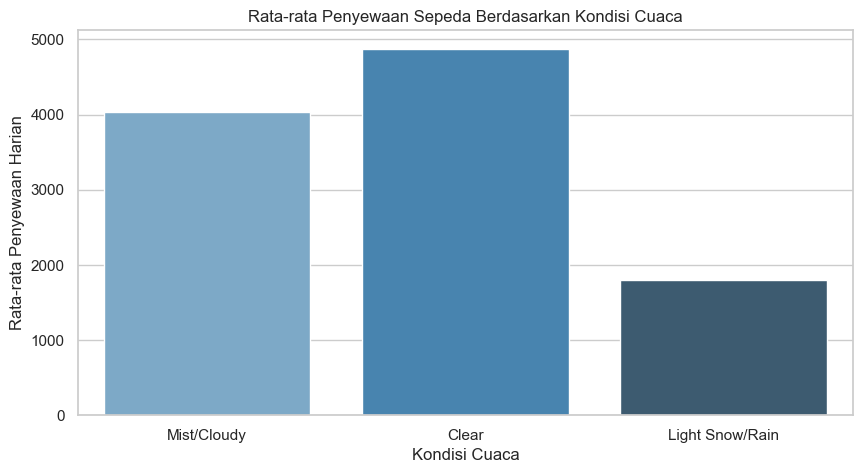

In [25]:
plt.figure(figsize=(10, 5))
sns.barplot(x='weathersit_label', y='cnt', data=day_df, palette='Blues_d', errorbar=None)
plt.title('Rata-rata Penyewaan Sepeda Berdasarkan Kondisi Cuaca')
plt.xlabel('Kondisi Cuaca')
plt.ylabel('Rata-rata Penyewaan Harian')
plt.show()

### Pertanyaan 2:

C:\Users\Alya\AppData\Local\Temp\ipykernel_22044\253159916.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=clear_days_grouped, x='weather_prev_day', y='cnt', palette='coolwarm')


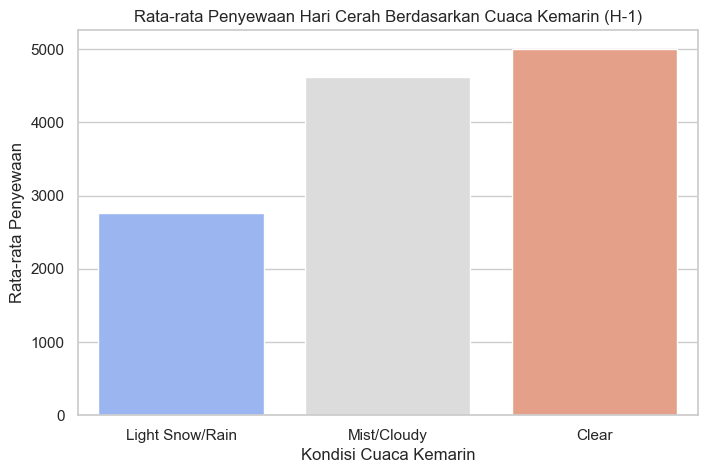

In [26]:
weather_order = ['Light Snow/Rain', 'Mist/Cloudy', 'Clear']
clear_days_grouped = clear_days.groupby('weather_prev_day')['cnt'].mean().reindex(weather_order).reset_index()

plt.figure(figsize=(8, 5))
sns.barplot(data=clear_days_grouped, x='weather_prev_day', y='cnt', palette='coolwarm')
plt.title('Rata-rata Penyewaan Hari Cerah Berdasarkan Cuaca Kemarin (H-1)')
plt.xlabel('Kondisi Cuaca Kemarin')
plt.ylabel('Rata-rata Penyewaan')
plt.show()

### Pertanyaan 2:

## Analisis Lanjutan (Opsional)

Rata-rata Penyewaan Berdasarkan Kategori Suhu:


,temp_category,mean,count
0,Dingin (<0.25),1703.174603,63
1,Sejuk (0.25-0.5),3758.453947,304
2,Hangat (0.5-0.75),5647.102894,311
3,Panas (>0.75),5406.792453,53


C:\Users\Alya\AppData\Local\Temp\ipykernel_22044\837868490.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=temp_analysis, x='temp_category', y='mean', palette='YlOrRd')


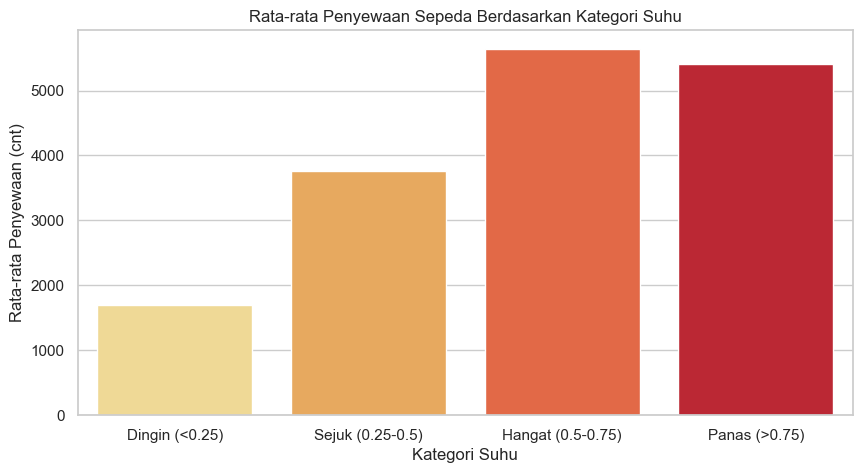

In [27]:
# Membuat binning (kategori) untuk kolom suhu (temp)
# Nilai temp pada dataset sudah dinormalisasi dari 0 sampai 1
bins = [0, 0.25, 0.5, 0.75, 1.0]
labels = ['Dingin (<0.25)', 'Sejuk (0.25-0.5)', 'Hangat (0.5-0.75)', 'Panas (>0.75)']
day_df['temp_category'] = pd.cut(day_df['temp'], bins=bins, labels=labels, include_lowest=True)

# Menghitung rata-rata penyewaan berdasarkan kategori suhu
temp_analysis = day_df.groupby('temp_category', observed=True)['cnt'].agg(['mean', 'count']).reset_index()
print("Rata-rata Penyewaan Berdasarkan Kategori Suhu:")
display(temp_analysis)

# Visualisasi Hasil Analisis Lanjutan
plt.figure(figsize=(10, 5))
sns.barplot(data=temp_analysis, x='temp_category', y='mean', palette='YlOrRd')
plt.title('Rata-rata Penyewaan Sepeda Berdasarkan Kategori Suhu')
plt.xlabel('Kategori Suhu')
plt.ylabel('Rata-rata Penyewaan (cnt)')
plt.show()

**Insight:** (Opsional)
- **Tren Suhu vs Penyewaan:** Terdapat hubungan positif yang sangat jelas antara suhu udara dengan minat penyewaan sepeda. Semakin hangat suhu, semakin banyak sepeda yang disewa.
-  **Puncak Penyewaan:** Rata-rata penyewaan tertinggi terjadi pada kategori suhu **Hangat (0.5-0.75)** dengan rata-rata **5.647 unit** (dari 311 hari), disusul oleh kategori **Panas (>0.75)** dengan rata-rata **5.406 unit** (dari 53 hari).
-   **Titik Terendah:** Pada kategori suhu **Dingin (<0.25)**, rata-rata penyewaan sangat terpuruk, hanya sekitar **1.703 unit** (dari 63 hari).
-  **Implikasi Bisnis:** Suhu yang terlalu panas (Panas >0.75) justru sedikit menurunkan minat dibandingkan suhu yang sejuk/hangat. Namun, faktor dingin adalah "musuh" terbesar. Manajemen perlu menyiapkan strategi khusus (seperti promo atau diskon) ketika suhu mulai dingin, karena secara alamiah pengguna akan enggan bersepeda di udara yang terlalu dingin.

## Conclusion & Recommendation

- **Conclusion Pertanyaan 1:** Berdasarkan hasil analisis, penyewaan sepeda mencapai titik terendah mutlak pada angka **22 unit** yang terjadi pada tanggal 29 Oktober 2012 ketika cuaca sedang **Light Snow/Rain**. Sebaran data juga menunjukkan bahwa mayoritas hari dengan penyewaan terendah (di bawah 600 unit) didominasi oleh kondisi cuaca yang tidak mendukung (Light Snow/Rain dan Mist/Cloudy). 
- **Conclusion Pertanyaan 2:** Terdapat indikasi kuat adanya **efek psikologis (trauma cuaca)**. Meskipun cuaca pada hari ini sedang **Cerah (Clear)**, rata-rata penyewaan harian sangat dipengaruhi oleh cuaca kemarin. Jika kemarin cerah, rata-rata penyewaan mencapai **5.008 unit**. Namun, jika kemarin terjadi hujan ringan (*Light Snow/Rain*), rata-rata penyewaan hari ini meskipun cerah langsung merosot menjadi **2.758 unit**. 

**Rekomendasi Action Item:**
1. **Mitigasi Cuaca Ekstrem (Berdasarkan Pertanyaan 1):** Saat prakiraan cuaca memprediksi adanya *Light Snow/Rain* atau cuaca berkabut, manajemen sebaiknya tidak mengalokasikan seluruh armada sepeda ke jalanan untuk menghindari penumpukan sepeda yang tidak terpakai. Fokuskan armada di stasiun yang dekat dengan area transit (seperti halte bus/stasiun) karena pengguna *registered* (komuter) tetap membutuhkan sepeda untuk jarak pendek meskipun hujan ringan.
2. **Strategi Promosi "Cuaca Cerah" (Berdasarkan Pertanyaan 2):** Karena cuaca cerah setelah hujan (H-1) memiliki minat yang lebih rendah, tim marketing dapat meluncurkan program promosi dadakan (seperti *Flash Sale* atau diskon 20%) pada jam 10.00 - 14.00 ketika cuaca hari ini cerah, guna memancing kembali minat pengguna yang ragu keluar rumah akibat ingat cuaca buruk kemarin.